# QuickDraw Mini-Project

Self-contained classification notebook. The only input files are `banana.npy`, `hockey_stick.npy`, and `mosquito.npy`. All preprocessing, model code, and metrics are defined here. No other data or saved result is loaded; this notebook does not save files.

Classes: banana, hockey stick, mosquito. Images: 28 x 28 grayscale.

## Experiment setup

Use up to 20,000 samples per class. Split the data stratified into 80% train, 10% validation, and 10% test with seed 42. Do not binarize pixels. Logistic regression and CNN use [0, 1] scaling; SVM uses [-1, 1]. Logistic regression: multinomial lbfgs, 100 iterations. SVM: linear, RBF, polynomial degree 5, sigmoid; 500 iterations. CNN: two convolution/pooling blocks, Adam, learning rate 0.001, batch size 64, 20 epochs. The test partition is held out for final evaluation.

In [1]:
from pathlib import Path
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED=42
CLASS_NAMES=['banana','hockey stick','mosquito']
SAMPLES_PER_CLASS=20_000
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR=Path.cwd()
print('Device:', DEVICE)

Device: cpu


## Load the only three permitted input arrays

Upload the three arrays into the notebook runtime current working directory. The notebook reads only from that directory; it does not search other folders. Each array must be shaped (N, 784) or (N, 28, 28).

banana.npy shape (307936, 28, 28) dtype uint8 selected 20000
hockey_stick.npy shape (130110, 28, 28) dtype uint8 selected 20000
mosquito.npy shape (123029, 28, 28) dtype uint8 selected 20000
Combined shape: (60000, 28, 28) counts: {'banana': 20000, 'hockey stick': 20000, 'mosquito': 20000}


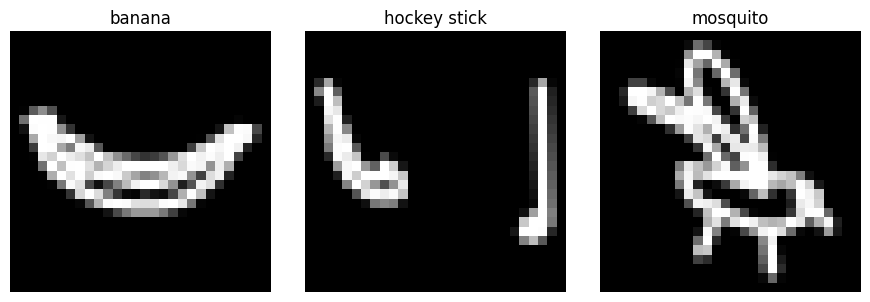

In [2]:
INPUT_NAMES=['banana.npy','hockey_stick.npy','mosquito.npy']
parts, label_parts, actual_counts=[],[],{}
for class_id, filename in enumerate(INPUT_NAMES):
    path=DATA_DIR/filename
    if not path.is_file(): raise FileNotFoundError(f'Missing required input: {path}')
    arr=np.load(path,mmap_mode='r',allow_pickle=False)
    if arr.ndim==2 and arr.shape[1]==784: arr=arr.reshape(-1,28,28)
    if arr.ndim!=3 or arr.shape[1:]!=(28,28): raise ValueError(f'Unexpected shape for {filename}: {arr.shape}')
    n=min(len(arr),SAMPLES_PER_CLASS)
    parts.append(np.asarray(arr[:n],dtype=np.uint8)); label_parts.append(np.full(n,class_id,dtype=np.int64))
    actual_counts[CLASS_NAMES[class_id]]=n
    print(filename, 'shape',arr.shape,'dtype',arr.dtype,'selected',n)
X=np.concatenate(parts); y=np.concatenate(label_parts)
print('Combined shape:',X.shape,'counts:',actual_counts)
fig,axes=plt.subplots(1,3,figsize=(9,3))
for i,ax in enumerate(axes):
    ax.imshow(X[np.flatnonzero(y==i)[0]],cmap='gray',vmin=0,vmax=255); ax.set_title(CLASS_NAMES[i]); ax.axis('off')
plt.tight_layout(); plt.show()

## Shared stratified split and normalization

Reuse one split for every model. Fixed pixel scaling does not learn from the test set.

In [3]:
idx=np.arange(len(y))
train_idx,rest=train_test_split(idx,test_size=.2,random_state=SEED,stratify=y)
val_idx,test_idx=train_test_split(rest,test_size=.5,random_state=SEED,stratify=y[rest])
for name,ids in [('train',train_idx),('validation',val_idx),('test',test_idx)]: print(name,len(ids),np.bincount(y[ids],minlength=3))
Xtr_raw,ytr=X[train_idx],y[train_idx]; Xte_raw,yte=X[test_idx],y[test_idx]
scale01=lambda a:a.astype(np.float32)/255.0
scalen11=lambda a:a.astype(np.float32)/127.5-1.0
Xtr_lr=scale01(Xtr_raw).reshape(len(train_idx),-1); Xte_lr=scale01(Xte_raw).reshape(len(test_idx),-1)
Xtr_svm=scalen11(Xtr_raw).reshape(len(train_idx),-1); Xte_svm=scalen11(Xte_raw).reshape(len(test_idx),-1)
Xtr_cnn=scale01(Xtr_raw); Xte_cnn=scale01(Xte_raw)

def score(y_true,y_pred):
    p,r,f,_=precision_recall_fscore_support(y_true,y_pred,average='macro',zero_division=0)
    return {'accuracy':float(accuracy_score(y_true,y_pred)),'macro_precision':float(p),'macro_recall':float(r),'macro_f1':float(f),'confusion_matrix':confusion_matrix(y_true,y_pred,labels=[0,1,2])}

train 48000 [16000 16000 16000]
validation 6000 [2000 2000 2000]
test 6000 [2000 2000 2000]


## Train classical models

Set `RUN_CLASSICAL=True` to fit logistic regression and the four SVM kernels. SVM training may be resource-intensive. Scores are measured on the held-out test partition.

In [4]:
RUN_CLASSICAL=True
results={}; fitted={}
if RUN_CLASSICAL:
    specs=[('Logistic Regression',LogisticRegression(solver='lbfgs',max_iter=100,random_state=SEED,n_jobs=-1),Xtr_lr,Xte_lr),
    ('SVM Linear',SVC(kernel='linear',max_iter=500,random_state=SEED),Xtr_svm,Xte_svm),
    ('SVM RBF',SVC(kernel='rbf',gamma=1.0,max_iter=500,random_state=SEED),Xtr_svm,Xte_svm),
    ('SVM Polynomial',SVC(kernel='poly',degree=5,coef0=1.0,max_iter=500,random_state=SEED),Xtr_svm,Xte_svm),
    ('SVM Sigmoid',SVC(kernel='sigmoid',coef0=1.0,max_iter=500,random_state=SEED),Xtr_svm,Xte_svm)]
    for name,model,xfit,xeval in specs:
        start=time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always'); model.fit(xfit,ytr)
        elapsed=time.perf_counter()-start; tic=time.perf_counter(); pred=model.predict(xeval); inf=time.perf_counter()-tic
        results[name]=score(yte,pred); results[name].update(training_seconds=elapsed,inference_seconds=inf); fitted[name]=model
        print(name, 'accuracy',round(results[name]['accuracy'],4),'seconds',round(elapsed,2))
        for w in caught: print('Warning:',w.message)
else: print('Skipped; set RUN_CLASSICAL=True to train.')

Logistic Regression accuracy 0.8335 seconds 14.83
SVM Linear accuracy 0.4308 seconds 37.93
SVM RBF accuracy 0.8023 seconds 43.23
SVM Polynomial accuracy 0.6793 seconds 39.21
SVM Sigmoid accuracy 0.4573 seconds 44.24


## CNN training and held-out evaluation

Set `RUN_CNN=True` to run 20 epochs. Training uses only the training partition; evaluation uses only the held-out test partition.

In [5]:
class QuickDrawCNN(nn.Module):
    def __init__(self):
        super().__init__(); self.features=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2)); self.head=nn.Sequential(nn.Flatten(),nn.Linear(64*7*7,128),nn.ReLU(),nn.Linear(128,3))
    def forward(self,x): return self.head(self.features(x))
RUN_CNN=True; EPOCHS=20; BATCH_SIZE=64; LEARNING_RATE=.001
cnn=None
if RUN_CNN:
    tx=torch.from_numpy(Xtr_cnn[:,None]); ty=torch.from_numpy(ytr)
    loader=DataLoader(TensorDataset(tx,ty),batch_size=BATCH_SIZE,shuffle=True)
    cnn=QuickDrawCNN().to(DEVICE); opt=torch.optim.Adam(cnn.parameters(),lr=LEARNING_RATE); loss_fn=nn.CrossEntropyLoss(); start=time.perf_counter()
    for epoch in range(EPOCHS):
        cnn.train(); total=0.
        for bx,by in loader:
            bx,by=bx.to(DEVICE),by.to(DEVICE); opt.zero_grad(); loss=loss_fn(cnn(bx),by); loss.backward(); opt.step(); total+=loss.item()*len(by)
        print(f'Epoch {epoch+1}/{EPOCHS}: loss={total/len(tx):.4f}')
    train_seconds=time.perf_counter()-start; cnn.eval(); te=torch.from_numpy(Xte_cnn[:,None]).to(DEVICE)
    with torch.no_grad(): tic=time.perf_counter(); logits=cnn(te); inf=time.perf_counter()-tic
    pred=logits.argmax(1).cpu().numpy(); p,r,f,_=precision_recall_fscore_support(yte,pred,average='macro',zero_division=0)
    results['CNN']={'accuracy':float(accuracy_score(yte,pred)),'macro_precision':float(p),'macro_recall':float(r),'macro_f1':float(f),'confusion_matrix':confusion_matrix(yte,pred,labels=[0,1,2]),'training_seconds':train_seconds,'inference_seconds':inf}
else: print('Skipped; set RUN_CNN=True to train.')

Epoch 1/20: loss=0.3047
Epoch 2/20: loss=0.1824
Epoch 3/20: loss=0.1524
Epoch 4/20: loss=0.1301
Epoch 5/20: loss=0.1155
Epoch 6/20: loss=0.1004
Epoch 7/20: loss=0.0847
Epoch 8/20: loss=0.0717
Epoch 9/20: loss=0.0580
Epoch 10/20: loss=0.0458
Epoch 11/20: loss=0.0348
Epoch 12/20: loss=0.0288
Epoch 13/20: loss=0.0231
Epoch 14/20: loss=0.0198
Epoch 15/20: loss=0.0176
Epoch 16/20: loss=0.0141
Epoch 17/20: loss=0.0125
Epoch 18/20: loss=0.0119
Epoch 19/20: loss=0.0115
Epoch 20/20: loss=0.0100


## Results from this run

Only scores calculated in this notebook are shown. No results are preloaded. Confusion matrices use true classes as rows and predicted classes as columns.

,Model,accuracy,macro_precision,macro_recall,macro_f1,training_seconds,inference_seconds
5,CNN,0.950000,0.950238,0.950000,0.949877,679.449397,4.480180
0,Logistic Regression,0.833500,0.833182,0.833500,0.832958,14.825696,0.032523
2,SVM RBF,0.802333,0.815961,0.802333,0.803405,43.234202,3.758937
3,SVM Polynomial,0.679333,0.715755,0.679333,0.687586,39.212185,4.935819
4,SVM Sigmoid,0.457333,0.539203,0.457333,0.390759,44.243288,2.940154
1,SVM Linear,0.430833,0.445872,0.430833,0.435225,37.930069,3.278607


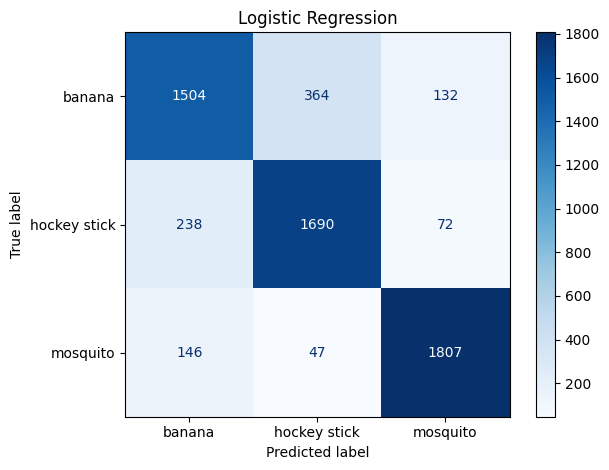

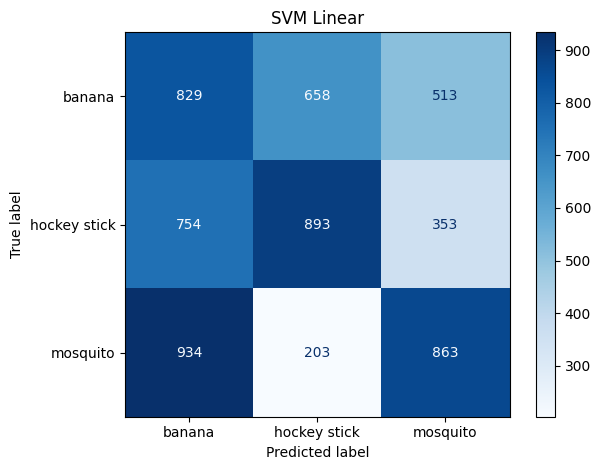

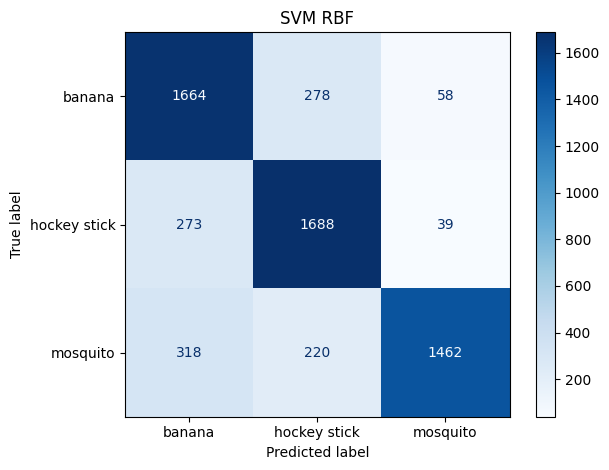

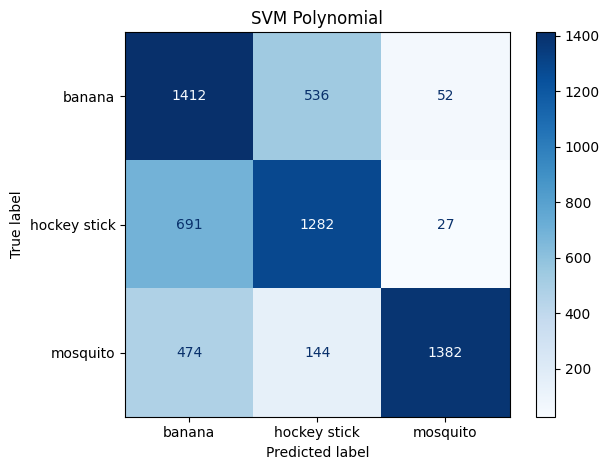

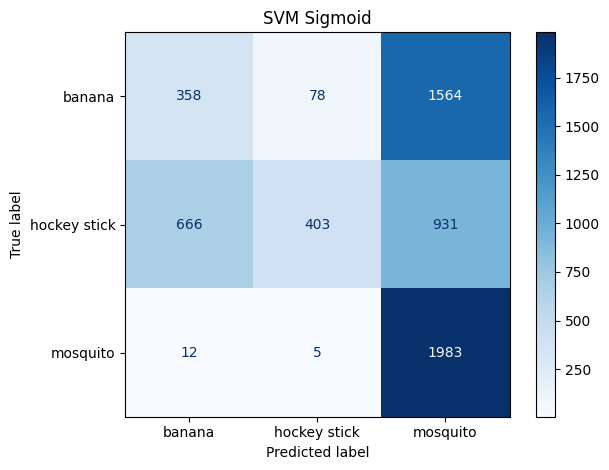

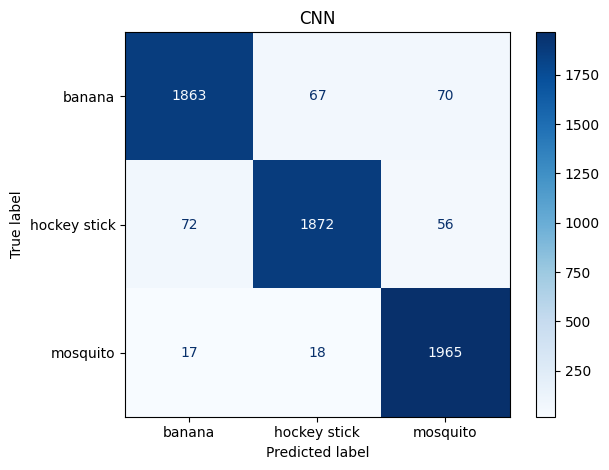

In [6]:
if not results:
    print('No models run yet. Enable training above.')
else:
    display(pd.DataFrame([{'Model':n,**{k:v for k,v in d.items() if k!='confusion_matrix'}} for n,d in results.items()]).sort_values('accuracy',ascending=False))
    for name,d in results.items():
        ConfusionMatrixDisplay(d['confusion_matrix'],display_labels=CLASS_NAMES).plot(cmap='Blues',values_format='d'); plt.title(name); plt.tight_layout(); plt.show()

## Transfer learning and conclusion

**Setup.** The experiment used 60,000 images, with 20,000 drawings in each of the banana, hockey stick, and mosquito classes. A stratified split assigned 48,000 images to training, 6,000 to validation, and 6,000 to testing, using seed 42. Images were not binarized. Scores below are from the held-out test set; the validation set was not used for model selection.

**Results.** The accuracy ranking is CNN (0.9500), logistic regression (0.8335), SVM RBF (0.8023), SVM polynomial (0.6793), SVM sigmoid (0.4573), and SVM linear (0.4308). The macro-F1 ranking differs only at the bottom, where linear and sigmoid swap: CNN (0.9499), logistic regression (0.8330), SVM RBF (0.8034), SVM polynomial (0.6876), SVM linear (0.4352), and SVM sigmoid (0.3908). The CNN has the strongest result across both measures and outperforms every SVM. Among SVMs, RBF performs best on both metrics; linear and sigmoid are weakest by accuracy and F1, respectively.

**Class-level errors.** In the CNN confusion matrix, banana drawings were labeled hockey stick 67 times and hockey sticks were labeled banana 72 times. Logistic regression made this reciprocal confusion 364 and 238 times, respectively. Mosquito was recognized more reliably: the CNN correctly classified 1,965 of 2,000 mosquitoes, confusing 17 with banana and 18 with hockey stick. Logistic regression correctly classified 1,807 mosquitoes; its remaining errors were 146 as banana and 47 as hockey stick.

**Efficiency.** Training times were CNN 679.45 seconds, logistic regression 14.83, RBF 43.23, polynomial 39.21, sigmoid 44.24, and linear 37.93. Full-test-set inference times were CNN 4.480 seconds, logistic regression 0.033, RBF 3.759, polynomial 4.936, sigmoid 2.940, and linear 3.279. The run used CPU; timings depend on the machine and runtime.

**Caveats.** Each SVM reached the 500-iteration cap and emitted a "Solver terminated early" warning. The SVMs were not tuned, so their ranking reflects this iteration-capped setup. The `datetime.utcnow()` deprecation warnings came from the environment. CNN training ended at loss 0.0100, but no validation learning curves were tracked, so overfitting was not measured directly.

**Transfer learning.** It was not run because pretrained weights are additional inputs beyond the three permitted arrays. A randomly initialized network would be training from scratch, not transfer learning.